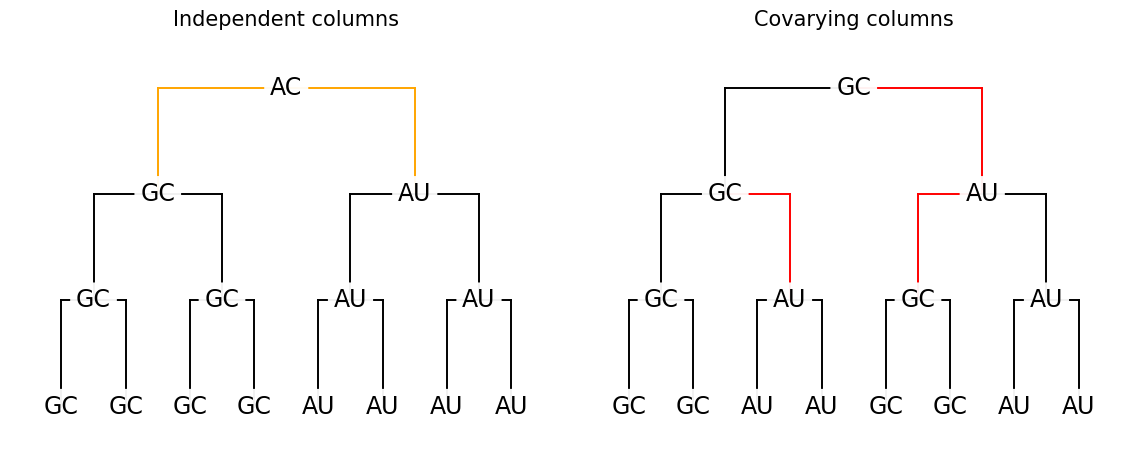

In [2]:
from io import StringIO

import numpy as np

import matplotlib.pyplot as plt

from Bio import Phylo



newick = "(((A:0.1,B:0.1)L1:0.1,(C:0.1,D:0.1)L2:0.1)L:0.1,((E:0.1,F:0.1)R1:0.1,(G:0.1,H:0.1)R2:0.1)R:0.1)Root;"



NODE_FONTSIZE = 17

TITLE_FONTSIZE = 15

SUPTITLE_FONTSIZE = 15



def build_tree():

    tree = Phylo.read(StringIO(newick), "newick")

    tree.rooted = True

    return tree



def draw_panel(ax, tip_pair, internal_pair, title, root_only=False):

    tree = build_tree()



    def node_label(clade):

        if clade.is_terminal():

            return tip_pair[clade.name]

        return internal_pair[clade.name]



    def mutation_size(parent, child):

        parent_label = node_label(parent)

        child_label = node_label(child)

        return sum(a != b for a, b in zip(parent_label, child_label))



    x_pos = tree.depths()

    if max(x_pos.values()) == 0:

        x_pos = tree.depths(unit_branch_lengths=False)



    tips = tree.get_terminals()

    y_pos = {t: i for i, t in enumerate(tips)}



    def set_internal_y(clade):

        for ch in clade.clades:

            set_internal_y(ch)

        if not clade.is_terminal():

            y_pos[clade] = np.mean([y_pos[ch] for ch in clade.clades])



    set_internal_y(tree.root)



    for parent in tree.find_clades(order="level"):

        for child in parent.clades:

            x0, x1 = x_pos[parent], x_pos[child]

            y0, y1 = y_pos[parent], y_pos[child]



            mut_size = mutation_size(parent, child)

            if root_only and parent != tree.root:

                mut_size = 0



            if mut_size == 1:

                branch_color = "orange"

            elif mut_size >= 2:

                branch_color = "red"

            else:

                branch_color = "black"



            ax.plot([y0, y1], [x0, x0], color=branch_color, lw=1.4)

            ax.plot([y1, y1], [x0, x1], color=branch_color, lw=1.4)



    for clade in tree.find_clades(order="preorder"):

        ax.text(

            y_pos[clade],

            x_pos[clade],

            node_label(clade),

            ha="center",

            va="center",

            fontsize=NODE_FONTSIZE,

            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.95),

        )



    ax.set_xlim(-0.8, len(tips) - 0.2)

    ax.set_ylim(max(x_pos.values()) + 0.05, -0.05)

    ax.axis("off")

    ax.set_title(title, fontsize=TITLE_FONTSIZE)



tip_pair_no_cov = {

    "A": "GC", "B": "GC", "C": "GC", "D": "GC",

    "E": "AU", "F": "AU", "G": "AU", "H": "AU",

}

internal_pair_no_cov = {

    "Root": "AC",

    "L": "GC",

    "L1": "GC",

    "L2": "GC",

    "R": "AU",

    "R1": "AU",

    "R2": "AU",

}



tip_pair_cov = {

    "A": "GC", "B": "GC", "C": "AU", "D": "AU",

    "E": "GC", "F": "GC", "G": "AU", "H": "AU",

}

internal_pair_cov = {

    "Root": "GC",

    "L": "GC",

    "L1": "GC",

    "L2": "AU",

    "R": "AU",

    "R1": "GC",

    "R2": "AU",

}



fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))

draw_panel(axes[0], tip_pair_no_cov, internal_pair_no_cov, "Independent columns", root_only=True)

draw_panel(axes[1], tip_pair_cov, internal_pair_cov, "Covarying columns", root_only=False)

plt.tight_layout()

plt.savefig("intro.pdf")

plt.show()
